# Data Slayer 4.0 — Exam Cheating Detection

In [1]:
DATA_DIR = "./data"      # berisi train/, test/, sample_submission.csv
DATA_ZIP = ""                # opsional (Colab): path zip dataset, mis. /content/drive/MyDrive/datasets.zip -> diekstrak ke DATA_DIR
WORK_DIR = "./work"          # cache (frame, fitur) — boleh dihapus kapan saja; butuh ±25 GB
OUT_DIR = "."                # tempat submission.csv ditulis (satu file saja)
SEED = 2026
N_FOLDS = 5
N_SEEDS = 2                  # bagging seed per fold
USE_STITCH = True            # S1: jahit sequence test menjadi video
USE_ASSIGN = True            # S2: penugasan satu-ke-satu per (subjek, kamera)
USE_FUSION = True            # S3: gabungkan bukti kamera front + side untuk aksi yang sama
USE_LOCALIZE = True          # S5: di video cheat, hanya detik sejak awal aksi curang yang diberi label 1
USE_VJEPA = True             # stream fitur kedua (V-JEPA 2)
SHOW_FRAMES = True           # tampilkan contoh frame berisi wajah di output EDA; jangan publikasikan notebook hasilnya
FAST = False                 # uji cepat pada subset kecil, bukan untuk submit

In [2]:
import os, sys, glob, json, math, time, random, hashlib, subprocess, warnings
from concurrent.futures import ThreadPoolExecutor   # thread, bukan proses: aman di Windows/Colab untuk fungsi yang didefinisikan di notebook

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.optimize import linear_sum_assignment
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import f1_score, confusion_matrix
from torch.utils.data import DataLoader, Dataset

warnings.filterwarnings("ignore")
# --- Google Colab (opsional): dataset privat diambil dari Google Drive milik sendiri, tidak ada yang diunggah ke mana pun
if "google.colab" in sys.modules and not os.path.isdir(f"{DATA_DIR}/train"):
    from google.colab import drive
    drive.mount("/content/drive")
if DATA_ZIP and not os.path.isdir(f"{DATA_DIR}/train"):
    import zipfile
    with zipfile.ZipFile(DATA_ZIP) as zf:
        root = os.path.dirname(os.path.abspath(DATA_DIR)) if any(n.startswith("datasets/") for n in zf.namelist()[:50]) else DATA_DIR
        zf.extractall(root)
assert os.path.isdir(f"{DATA_DIR}/train") and os.path.isdir(f"{DATA_DIR}/test"), f"dataset tidak ditemukan di {os.path.abspath(DATA_DIR)}"
FAST = str(FAST).lower() in ("1", "true"); USE_STITCH = str(USE_STITCH).lower() in ("1", "true")
USE_ASSIGN = str(USE_ASSIGN).lower() in ("1", "true"); USE_VJEPA = str(USE_VJEPA).lower() in ("1", "true")
USE_FUSION = str(USE_FUSION).lower() in ("1", "true")
SHOW_FRAMES = str(SHOW_FRAMES).lower() in ("1", "true")
SEED, N_FOLDS, N_SEEDS = int(SEED), int(N_FOLDS), int(N_SEEDS)
for d in (WORK_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)
FR_DIR = f"{WORK_DIR}/frames"
os.makedirs(f"{FR_DIR}/train", exist_ok=True)


def save_npy(path, arr):          # tulis atomik: cache yang terpotong tidak akan dianggap lengkap pada run berikutnya
    tmp = path + ".tmp.npy"
    np.save(tmp, arr)
    os.replace(tmp, path)


def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


seed_all(SEED)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
assert DEV == "cuda", "Notebook ini butuh GPU CUDA (lokal, atau di Colab: Runtime > Change runtime type > GPU)."
N_CPU = os.cpu_count() or 4
print("python", sys.version.split()[0], "| torch", torch.__version__, "| cv2", cv2.__version__, "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| sklearn", sklearn.__version__, "| pandas", pd.__version__)
print("device:", DEV, torch.cuda.get_device_name(0) if DEV == "cuda" else "", "| cpus:", N_CPU)
T_START = time.time()

NORMAL = ["Writing_Answers", "Thinking", "Looking_Around", "Checking_Smartwatch"]
CHEAT = ["Looking_Under_the_Desk", "Reading_Hidden_Notes", "Repeated_Peeking", "Using_Smartwatch"]
BEHAVIOURS = NORMAL + CHEAT          # indeks >= 4  <=>  cheat
CLIP = 30                            # frame per sequence test (1 detik @30fps)

python 3.11.15 | torch 2.11.0+cu128 | cv2 5.0.0 | numpy 2.4.6 | scipy 1.17.1 | sklearn 1.9.1 | pandas 3.1.1
device: cuda NVIDIA GeForce RTX 5070 Ti Laptop GPU | cpus: 20


## 1. Inventaris data

In [3]:
rows = []
for p in sorted(glob.glob(f"{DATA_DIR}/train/*/*/*.MOV")):
    cls, subj, fn = p.replace("\\", "/").split("/")[-3:]
    view, beh = fn[:-4].split("_", 1)
    rows.append(dict(path=p, key=f"{cls}__{subj}__{view}__{beh}", cls=cls, subject=int(subj.split("_")[1]), view=view,
                     behaviour=beh, y8=BEHAVIOURS.index(beh), y=int(cls == "cheat")))
meta = pd.DataFrame(rows).sort_values(["subject", "view", "y8"]).reset_index(drop=True)
assert (meta.y == (meta.y8 >= 4)).all(), "label folder dan nama perilaku tidak konsisten"
if FAST:
    meta = meta[meta.subject.isin(sorted(meta.subject.unique())[:8])].reset_index(drop=True)
test_ids = sorted(os.listdir(f"{DATA_DIR}/test"))
sub_tmpl = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
assert set(sub_tmpl.id) == set(test_ids), "id sample_submission != folder test"
print(f"train: {len(meta)} video | {meta.subject.nunique()} subjek | per subjek {meta.groupby('subject').size().unique().tolist()} video")
print(f"test : {len(test_ids)} sequence | kolom submission: {list(sub_tmpl.columns)}")
display(pd.crosstab(meta.behaviour, [meta.cls, meta.view]))

train: 416 video | 26 subjek | per subjek [16] video
test : 1515 sequence | kolom submission: ['id', 'label']


cls                    cheat      normal     
view                   front side  front side
behaviour                                    
Checking_Smartwatch        0    0     26   26
Looking_Around             0    0     26   26
Looking_Under_the_Desk    26   26      0    0
Reading_Hidden_Notes      26   26      0    0
Repeated_Peeking          26   26      0    0
Thinking                   0    0     26   26
Using_Smartwatch          26   26      0    0
Writing_Answers            0    0     26   26

## 2. EDA

In [4]:
def probe(p):
    cap = cv2.VideoCapture(p)
    out = dict(w=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), h=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
               fps=round(cap.get(cv2.CAP_PROP_FPS), 2), n_meta=int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
    cap.release()
    return out


with ThreadPoolExecutor(8) as ex:
    pr = pd.DataFrame(list(ex.map(probe, meta.path)))
meta[["w", "h", "fps", "n_meta"]] = pr.values
meta["dur_s"] = meta.n_meta / meta.fps
print("resolusi train:", meta.groupby(["w", "h"]).size().to_dict())
display(meta.groupby("view")[["fps", "n_meta", "dur_s"]].agg(["min", "mean", "max"]).round(2))


def ffprobe_pix(p):
    try:
        r = subprocess.run(["ffprobe", "-v", "error", "-select_streams", "v:0", "-show_entries", "stream=pix_fmt,color_transfer",
                            "-of", "csv=p=0", p], capture_output=True, text=True, timeout=30)
        return r.stdout.strip()
    except Exception:
        return "ffprobe tidak tersedia"


pix = pd.Series([ffprobe_pix(p) for p in meta.groupby("view").path.head(6)], index=meta.groupby("view").view.head(6).values)
print("pixel format / transfer (contoh 6 video per kamera):")
print(pix.groupby(level=0).value_counts().to_string())

t_sizes, t_counts = {}, {}
for s in test_ids[:: max(1, len(test_ids) // 150)]:
    fs = sorted(os.listdir(f"{DATA_DIR}/test/{s}"))
    t_counts[len(fs)] = t_counts.get(len(fs), 0) + 1
    im = cv2.imread(f"{DATA_DIR}/test/{s}/{fs[0]}")
    t_sizes[im.shape[:2]] = t_sizes.get(im.shape[:2], 0) + 1
print("test — jumlah frame per sequence:", t_counts, "| ukuran (h, w):", t_sizes)
TEST_H, TEST_W = max(t_sizes, key=t_sizes.get)
try:                                    # apakah tabel kuantisasi JPEG test sama dengan hasil OpenCV kualitas 95?
    import io
    from PIL import Image
    _p0 = f"{DATA_DIR}/test/{test_ids[0]}/{sorted(os.listdir(f'{DATA_DIR}/test/{test_ids[0]}'))[0]}"
    _q_test = Image.open(_p0).quantization
    _q_cv = Image.open(io.BytesIO(cv2.imencode(".jpg", cv2.imread(_p0), [cv2.IMWRITE_JPEG_QUALITY, 95])[1].tobytes())).quantization
    print("tabel kuantisasi JPEG test == OpenCV kualitas 95:", all(list(_q_test[k]) == list(_q_cv[k]) for k in _q_test))
except Exception as e:
    print("pemeriksaan tabel kuantisasi dilewati:", e)

resolusi train: {(1280.0, 720.0): 416}


fps               n_meta                 dur_s              
         min   mean    max    min    mean    max    min   mean    max
view                                                                 
front  30.00  30.00  30.00  407.0  474.24  539.0  13.57  15.81  17.97
side   29.97  29.97  29.98  431.0  487.10  558.0  14.38  16.25  18.62

pixel format / transfer (contoh 6 video per kamera):
front  yuv420p10le,arib-std-b67    6
side   yuv420p,bt709               6


test — jumlah frame per sequence: {30: 152} | ukuran (h, w): {(360, 640): 152}
tabel kuantisasi JPEG test == OpenCV kualitas 95: True


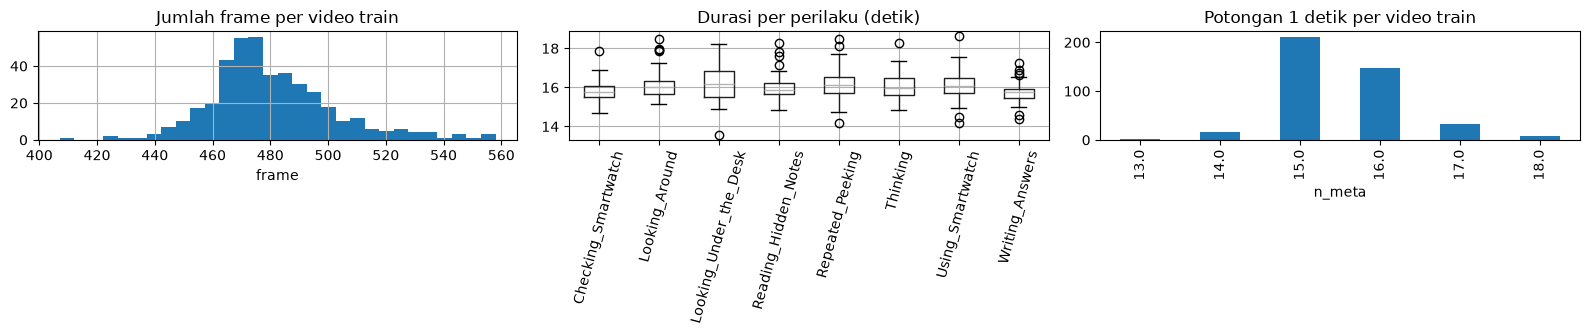

total potongan 1 detik di train: 6456.0 | rata-rata per video 15.52 | test: 1515 sequence ≈ 97.6 video


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
meta.n_meta.hist(bins=30, ax=ax[0]); ax[0].set_title("Jumlah frame per video train"); ax[0].set_xlabel("frame")
meta.boxplot(column="dur_s", by="behaviour", ax=ax[1], rot=75); ax[1].set_title("Durasi per perilaku (detik)"); ax[1].set_xlabel("")
(meta.n_meta // CLIP).value_counts().sort_index().plot.bar(ax=ax[2]); ax[2].set_title("Potongan 1 detik per video train")
plt.suptitle(""); plt.tight_layout(); plt.show()
print(f"total potongan 1 detik di train: {(meta.n_meta // CLIP).sum()} | rata-rata per video {(meta.n_meta // CLIP).mean():.2f}"
      f" | test: {len(test_ids)} sequence ≈ {len(test_ids) / (meta.n_meta // CLIP).mean():.1f} video")

### 2.1 Contoh perilaku

In [6]:
def filmstrip(path, n=8, w=200):
    cap = cv2.VideoCapture(path)
    nf = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    want = set(np.linspace(10, nf - 11, n).astype(int).tolist())
    out, i = [], 0
    while True:
        ok, f = cap.read()
        if not ok:
            break
        if i in want:
            out.append(cv2.resize(f, (w, w * 9 // 16), interpolation=cv2.INTER_AREA)[:, :, ::-1])
        i += 1
    cap.release()
    return np.hstack(out[:n])


if SHOW_FRAMES:
    s0 = int(meta.subject.iloc[len(meta) // 2])
    for view in ("front", "side"):
        m = meta[(meta.subject == s0) & (meta.view == view)].sort_values("y8")
        fig, ax = plt.subplots(8, 1, figsize=(16, 9.2))
        for a, (_, r) in zip(ax, m.iterrows()):
            a.imshow(filmstrip(r.path)); a.axis("off")
            a.set_title(f"{r.cls.upper()} — {r.behaviour}", fontsize=9, loc="left", color="crimson" if r.y else "darkgreen", pad=1)
        plt.suptitle(f"subject_{s0} — kamera {view}", y=1.0); plt.tight_layout(); plt.show()

## 3. Preprocessing — meniru pipeline pembuatan test

In [7]:
def extract_video(job):
    """decode -> resize (2x persis, INTER_AREA == INTER_LINEAR) -> JPEG q95; simpan byte JPEG berurutan + offset."""
    path, key = job
    f_bin, f_idx = f"{FR_DIR}/train/{key}.bin", f"{FR_DIR}/train/{key}.npy"
    if os.path.exists(f_idx) and os.path.exists(f_bin):
        return key, len(np.load(f_idx)) - 1
    cap = cv2.VideoCapture(path)
    offs = [0]
    with open(f_bin + ".tmp", "wb") as f:
        while True:
            ok, fr = cap.read()
            if not ok:
                break
            fr = cv2.resize(fr, (TEST_W, TEST_H), interpolation=cv2.INTER_AREA)
            ok, buf = cv2.imencode(".jpg", fr, [cv2.IMWRITE_JPEG_QUALITY, 95])
            f.write(buf.tobytes()); offs.append(offs[-1] + len(buf))
    cap.release()
    os.replace(f_bin + ".tmp", f_bin)
    save_npy(f_idx, np.array(offs, np.int64))
    return key, len(offs) - 1


t0 = time.time()
cv2.setNumThreads(1)                       # paralelisme lewat thread per video (OpenCV melepas GIL saat decode)
with ThreadPoolExecutor(N_CPU) as ex:
    nfr = dict(ex.map(extract_video, zip(meta.path, meta.key)))
meta["n_frames"] = meta.key.map(nfr)
_short = meta[meta.n_frames < 0.9 * meta.n_meta]     # decode terpotong? (jumlah frame hasil decode vs metadata kontainer)
assert len(_short) == 0, f"decode terpotong pada {len(_short)} video: {_short.key.tolist()[:5]} — hapus cache frame-nya lalu ulangi"
meta["n_clips"] = meta.n_frames // CLIP
print(f"train: {meta.n_frames.sum()} frame dari {len(meta)} video ({time.time() - t0:.0f}s) | potongan 1 detik: {meta.n_clips.sum()}")

f_bin, f_idx = f"{FR_DIR}/test.bin", f"{FR_DIR}/test.npy"
if not os.path.exists(f_idx):
    t0 = time.time()

    def _rd(s):
        fs = sorted(os.listdir(f"{DATA_DIR}/test/{s}"))
        assert len(fs) == CLIP, f"{s}: {len(fs)} frame"
        return [open(f"{DATA_DIR}/test/{s}/{x}", "rb").read() for x in fs]

    offs = [0]
    with ThreadPoolExecutor(32) as ex, open(f_bin + ".tmp", "wb") as f:
        for blobs in ex.map(_rd, test_ids):
            for b in blobs:
                f.write(b); offs.append(offs[-1] + len(b))
    os.replace(f_bin + ".tmp", f_bin)
    save_npy(f_idx, np.array(offs, np.int64))
    print(f"test: {len(test_ids)} sequence dipaketkan ({time.time() - t0:.0f}s)")
TEST_OFFS = np.load(f_idx)
assert len(TEST_OFFS) - 1 == len(test_ids) * CLIP
TRAIN_OFFS = {k: np.load(f"{FR_DIR}/train/{k}.npy") for k in meta.key}


def read_jpeg(path, a, b):
    with open(path, "rb") as f:
        f.seek(int(a))
        return cv2.imdecode(np.frombuffer(f.read(int(b - a)), np.uint8), cv2.IMREAD_COLOR)


def train_frame(key, j):
    o = TRAIN_OFFS[key]
    return read_jpeg(f"{FR_DIR}/train/{key}.bin", o[j], o[j + 1])


def test_frame(s, j):
    return read_jpeg(f"{FR_DIR}/test.bin", TEST_OFFS[s * CLIP + j], TEST_OFFS[s * CLIP + j + 1])

train: 199957 frame dari 416 video (0s) | potongan 1 detik: 6456


### 3.1 Uji paritas train ↔ test (per kamera)

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

N_TEST = len(test_ids)
clip_tab = pd.DataFrame([(i, c) for i, n in enumerate(meta.n_clips) for c in range(n)], columns=["vid", "pos"])   # potongan 1 detik train
clip_tab["subject"] = meta.subject.values[clip_tab.vid]; clip_tab["view"] = meta.view.values[clip_tab.vid]
N_TRC = len(clip_tab)


def thumb(img, w=160, h=90):
    return cv2.resize(img, (w, h), interpolation=cv2.INTER_AREA)


def bound_train(r):       # frame ke-1, 2, 29, 30 dari sebuah potongan train (thumbnail 160x90)
    k, base = meta.key[r.vid], r.pos * CLIP
    return np.stack([thumb(train_frame(k, base + j)) for j in (0, 1, CLIP - 2, CLIP - 1)])


def bound_test(s):
    return np.stack([thumb(test_frame(s, j)) for j in (0, 1, CLIP - 2, CLIP - 1)])


t0 = time.time()
with ThreadPoolExecutor(min(16, N_CPU)) as ex:
    B_TR = np.stack(list(ex.map(bound_train, clip_tab.itertuples(index=False))))
    B_TE = np.stack(list(ex.map(bound_test, range(N_TEST))))
print(f"thumbnail batas: train {B_TR.shape}, test {B_TE.shape} ({time.time() - t0:.0f}s)")


def tiny(B):  # thumbnail 16x9 dari frame pertama
    n = len(B)
    return B[:, 0].reshape(n, 9, 10, 16, 10, 3).mean((2, 4)).reshape(n, -1).astype(np.float32)


Xv, yv = tiny(B_TR), (clip_tab.view.values == "side").astype(int)
subs = np.array(sorted(meta.subject.unique()))
acc = []
for part in np.array_split(np.random.default_rng(SEED).permutation(subs), N_FOLDS):   # CV per subjek
    va = np.isin(clip_tab.subject.values, part)
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)).fit(Xv[~va], yv[~va])
    acc.append((clf.predict(Xv[va]) == yv[va]).mean())
view_clf = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)).fit(Xv, yv)
p_side = view_clf.predict_proba(tiny(B_TE))[:, 1]
TEST_VIEW = np.where(p_side > 0.5, "side", "front")
print(f"classifier kamera — akurasi CV per subjek: {np.mean(acc):.4f} (min {np.min(acc):.4f}) | "
      f"test: front {np.sum(TEST_VIEW == 'front')}, side {np.sum(TEST_VIEW == 'side')}, "
      f"prediksi ragu (0.1<p<0.9): {int(((p_side > 0.1) & (p_side < 0.9)).sum())}")


def img_stats(img):
    g = img.mean(-1)
    return [img[..., 2].mean(), img[..., 1].mean(), img[..., 0].mean(), g.std(), np.percentile(g, 50), np.percentile(g, 99),
            cv2.Laplacian(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), cv2.CV_32F).var()]


rng = np.random.default_rng(SEED)
tr_s = clip_tab.sample(min(600, N_TRC), random_state=SEED)
te_s = rng.choice(N_TEST, min(600, N_TEST), replace=False)
with ThreadPoolExecutor(min(16, N_CPU)) as ex:
    S_tr = np.array(list(ex.map(lambda r: img_stats(train_frame(meta.key[r.vid], r.pos * CLIP + 14)), tr_s.itertuples(index=False))))
    S_te = np.array(list(ex.map(lambda s: img_stats(test_frame(int(s), 14)), te_s)))
cols = ["R", "G", "B", "kontras", "median", "p99", "ketajaman(Laplacian)"]
par = []
for v in ("front", "side"):
    a, b = S_tr[tr_s.view.values == v], S_te[TEST_VIEW[te_s] == v]
    par += [pd.Series(a.mean(0), cols, name=f"train-sim {v}"), pd.Series(b.mean(0), cols, name=f"test {v}")]
par = pd.DataFrame(par).round(1)
display(par)
for v in ("front", "side"):
    d = (par.loc[f"train-sim {v}"] - par.loc[f"test {v}"]).abs()
    assert d[["R", "G", "B", "median"]].max() < 15 and d["p99"] < 8, f"PARITAS GAGAL untuk kamera {v}: {d.to_dict()}"
    r = par.loc[f"train-sim {v}", cols[-1]] / par.loc[f"test {v}", cols[-1]]
    assert 0.6 < r < 1.6, f"ketajaman tidak cocok untuk kamera {v} (rasio {r:.2f})"
print("PARITAS OK — pipeline decode/resize/JPEG train cocok dengan test untuk kedua kamera.")

thumbnail batas: train (6456, 4, 90, 160, 3), test (1515, 4, 90, 160, 3) (6s)


classifier kamera — akurasi CV per subjek: 1.0000 (min 1.0000) | test: front 742, side 773, prediksi ragu (0.1<p<0.9): 0


,R,G,B,kontras,median,p99,ketajaman(Laplacian)
train-sim front,189.2,182.0,180.0,63.1,214.5,246.8,771.1
test front,184.3,176.0,174.9,64.5,206.0,247.8,744.6
train-sim side,162.2,149.8,144.6,68.2,187.5,223.0,1096.7
test side,160.5,149.2,144.9,69.6,187.8,219.7,888.9


PARITAS OK — pipeline decode/resize/JPEG train cocok dengan test untuk kedua kamera.


In [9]:
if SHOW_FRAMES:
    fig, ax = plt.subplots(2, 6, figsize=(18, 3.6))
    pick_tr = [clip_tab[clip_tab.view == v].sample(3, random_state=SEED + i) for i, v in enumerate(("front", "side"))]
    pick_te = [rng.choice(np.where(TEST_VIEW == v)[0], 3, replace=False) for v in ("front", "side")]
    for j, r in enumerate(pd.concat(pick_tr).itertuples(index=False)):
        ax[0, j].imshow(train_frame(meta.key[r.vid], r.pos * CLIP)[:, :, ::-1]); ax[0, j].set_title(f"train-sim · {r.view}", fontsize=9)
    for j, s in enumerate(np.concatenate(pick_te)):
        ax[1, j].imshow(test_frame(int(s), 0)[:, :, ::-1]); ax[1, j].set_title(f"test · {TEST_VIEW[s]}", fontsize=9)
    [a.axis("off") for a in ax.ravel()]; plt.tight_layout(); plt.show()

## 4. Struktur tersembunyi test: sequence = potongan video yang berurutan

In [10]:
def link_costs(B, k=10):
    """biaya sambungan (N,N) — eksak (L1) hanya untuk k kandidat terdekat (prefilter L2 via BLAS) — dan noise antar-frame."""
    N = len(B)
    X = B.reshape(N, 4, -1).astype(np.float32)
    F1, F2, L29, L30 = X[:, 0], X[:, 1], X[:, 2], X[:, 3]
    d2 = (L30 ** 2).sum(1)[:, None] + (F1 ** 2).sum(1)[None] - 2.0 * (L30 @ F1.T)
    np.fill_diagonal(d2, np.inf)
    k = min(k, N - 1)
    cand = np.argpartition(d2, k - 1, axis=1)[:, :k]
    C = np.full((N, N), 1e6, np.float32)
    ex_tail, ex_head = 2 * L30 - L29, 2 * F1 - F2
    for i in range(N):
        js = cand[i]
        a = np.abs(F1[js] - L30[i]).mean(1)
        e = 0.5 * (np.abs(F1[js] - ex_tail[i]).mean(1) + np.abs(ex_head[js] - L30[i]).mean(1))
        C[i, js] = np.minimum(a, e)
    noise = 0.5 * (np.abs(F1 - F2).mean(1) + np.abs(L29 - L30).mean(1))
    return C, noise


def chains_from_links(nxt, N, C):
    has_prev, chains, seen = set(nxt.values()), [], set()
    for s in range(N):
        if s in has_prev:
            continue
        ch = [s]; seen.add(s)
        while ch[-1] in nxt and nxt[ch[-1]] not in seen:
            ch.append(nxt[ch[-1]]); seen.add(ch[-1])
        chains.append(ch)
    rest = [i for i in range(N) if i not in seen]
    while rest:  # siklus murni: putus di sambungan terlemah
        ch = [rest[0]]
        while nxt[ch[-1]] != ch[0]:
            ch.append(nxt[ch[-1]])
        w = int(np.argmax([C[ch[t], nxt[ch[t]]] for t in range(len(ch))]))
        ch = ch[w + 1:] + ch[:w + 1]
        chains.append(ch); seen.update(ch)
        rest = [i for i in range(N) if i not in seen]
    return chains


def stitch(B, tau_mult, max_len, costs=None):
    N = len(B)
    C, noise = costs if costs is not None else link_costs(B)
    tau = float(tau_mult * np.median(noise))
    A = np.concatenate([np.minimum(C, 10 * tau), np.full((N, N), tau, np.float32)], 1)   # kolom dummy = "tanpa penerus"
    r, c = linear_sum_assignment(A)
    nxt = {int(i): int(j) for i, j in zip(r, c) if j < N and C[i, j] < tau}
    out, stack = [], chains_from_links(nxt, N, C)
    while stack:  # rantai yang terlalu panjang untuk satu video diputus di sambungan terlemah
        ch = stack.pop()
        if len(ch) > max_len:
            w = int(np.argmax([C[a, b] for a, b in zip(ch[:-1], ch[1:])]))
            stack += [ch[:w + 1], ch[w + 1:]]
        else:
            out.append(ch)
    out.sort(key=lambda ch: ch[0])
    return out, C, tau


def stitch_score(chains, vid, pos):
    links = [(a, b) for c in chains for a, b in zip(c[:-1], c[1:])]
    wrong = sum(int(not (vid[a] == vid[b] and pos[b] == pos[a] + 1)) for a, b in links)
    whole = sum(int(len(set(vid[c])) == 1 and len(c) == int(np.sum(vid == vid[c[0]]))) for c in chains)
    pure = sum(int(np.unique(vid[c], return_counts=True)[1].max()) for c in chains) / len(vid)
    return dict(rantai=len(chains), video_asli=len(set(vid.tolist())), sambungan=len(links), sambungan_salah=wrong, video_utuh=whole, kemurnian_klip=round(pure, 4))


MAX_LEN = int(meta.n_clips.max()) + 1          # video terpanjang di train + toleransi 1 klip (ditetapkan a-priori)
N_SUBJ_SIM = max(2, int(round(N_TEST / meta.n_clips.mean() / 16)))   # ukuran simulasi ≈ ukuran test
TAU_GRID = [3.0, 4.0, 5.0, 6.0, 8.0]
rows, rng = [], np.random.default_rng(SEED)
for rep in range(4 if FAST else 8):
    ss = rng.choice(subs, min(N_SUBJ_SIM, len(subs)), replace=False)
    idx = np.where(np.isin(clip_tab.subject.values, ss))[0]
    idx = idx[rng.permutation(len(idx))]                      # id diacak seperti test
    costs = link_costs(B_TR[idx])
    for tm in TAU_GRID:
        ch, _, _ = stitch(B_TR[idx], tm, MAX_LEN, costs)
        rows.append(dict(rep=rep, tau_mult=tm, n_klip=len(idx), **stitch_score(ch, clip_tab.vid.values[idx], clip_tab.pos.values[idx])))
sim = pd.DataFrame(rows)
summ = sim.groupby("tau_mult").agg(sambungan_salah=("sambungan_salah", "sum"), video_utuh=("video_utuh", "sum"), video_asli=("video_asli", "sum"),
                                   rantai=("rantai", "sum"), kemurnian_klip=("kemurnian_klip", "mean"))
summ["skor"] = summ.video_utuh - 10 * summ.sambungan_salah
TAU_MULT = float(summ.skor.idxmax())
display(summ)
print(f"simulasi train ({N_SUBJ_SIM} subjek per ulangan): tau_mult terpilih = {TAU_MULT} → "
      f"{summ.loc[TAU_MULT, 'video_utuh']}/{summ.loc[TAU_MULT, 'video_asli']} video pulih utuh, {summ.loc[TAU_MULT, 'sambungan_salah']} sambungan salah")

,sambungan_salah,video_utuh,video_asli,rantai,kemurnian_klip,skor
tau_mult,,,,,,
3.0,0,694,768,872,1.0,694
4.0,0,747,768,797,1.0,747
5.0,0,761,768,781,1.0,761
6.0,0,765,768,771,1.0,765
8.0,0,753,768,785,1.0,753


simulasi train (6 subjek per ulangan): tau_mult terpilih = 6.0 → 765/768 video pulih utuh, 0 sambungan salah


test: 1515 sequence → 97 rantai | panjang: {7: 1, 9: 1, 14: 2, 15: 37, 16: 39, 17: 15, 18: 1, 19: 1}
rantai campur kamera: 0 | estimasi jumlah video dari panjang rata-rata train: 97.6


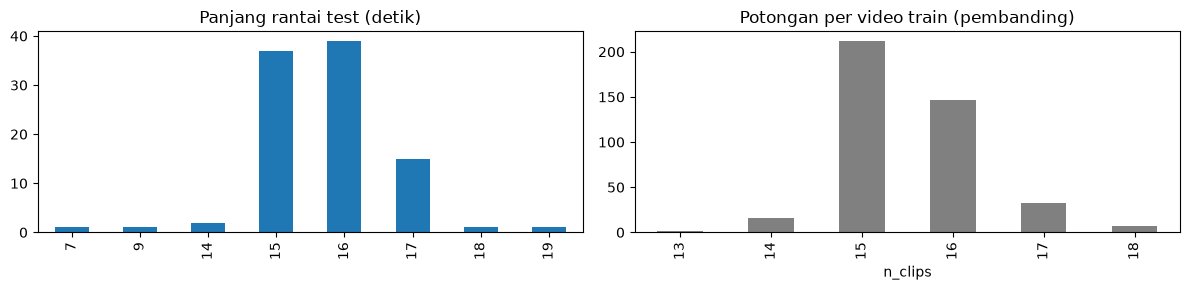

In [11]:
if USE_STITCH:
    TEST_CHAINS, C_TE, _ = stitch(B_TE, TAU_MULT, MAX_LEN)
else:
    TEST_CHAINS, C_TE = [[i] for i in range(N_TEST)], None
lens = pd.Series([len(c) for c in TEST_CHAINS])
mixed = sum(len(set(TEST_VIEW[c])) > 1 for c in TEST_CHAINS)
print(f"test: {N_TEST} sequence → {len(TEST_CHAINS)} rantai | panjang: {lens.value_counts().sort_index().to_dict()}")
print(f"rantai campur kamera: {mixed} | estimasi jumlah video dari panjang rata-rata train: {N_TEST / meta.n_clips.mean():.1f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
lens.value_counts().sort_index().plot.bar(ax=ax[0]); ax[0].set_title("Panjang rantai test (detik)")
meta.n_clips.value_counts().sort_index().plot.bar(ax=ax[1], color="gray"); ax[1].set_title("Potongan per video train (pembanding)")
plt.tight_layout(); plt.show()

## 5. Ekstraksi fitur dengan *foundation model* beku

In [12]:
import re

def _ensure(pkg, spec, bad=lambda v: False):
    """pasang paket bila belum ada ATAU versinya tidak cocok (mis. Colab membawa transformers 5.x)"""
    import importlib.metadata as md
    try:
        v = md.version(pkg)
    except md.PackageNotFoundError:
        v = None
    if v is None or bad(v):
        print(f"memasang {spec} (terpasang: {v})")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", spec], check=True)


_ensure("timm", "timm")
if USE_VJEPA:
    _ensure("transformers", "transformers==4.57.1",
            bad=lambda v: tuple(int(x) for x in re.findall(r"\d+", v)[:2]) < (4, 53) or int(re.findall(r"\d+", v)[0]) >= 5)
import timm
print("timm", timm.__version__)

FEAT_DIR = f"{WORK_DIR}/feat"
STRIDE = 3                      # 30 fps -> 10 frame fitur per detik
FPC_A = CLIP // STRIDE
_MM = {}


def blob(path):
    m = _MM.get(path)
    if m is None:
        m = _MM[path] = np.memmap(path, dtype=np.uint8, mode="r")
    return m


def decode_rgb(path, a, b):
    return cv2.imdecode(np.asarray(blob(path)[int(a):int(b)]), cv2.IMREAD_COLOR)[:, :, ::-1]


def batch_iter(items, bs, load_one, n_threads=min(12, N_CPU), prefetch=3):
    """batch uint8 lewat thread (cv2 melepas GIL) — tanpa multiprocessing, aman di Windows maupun Colab."""
    import itertools
    from collections import deque
    inner, outer = ThreadPoolExecutor(n_threads), ThreadPoolExecutor(prefetch)
    chunks = (items[i:i + bs] for i in range(0, len(items), bs))
    load = lambda ch: torch.from_numpy(np.stack(list(inner.map(load_one, ch))))
    q = deque(outer.submit(load, ch) for ch in itertools.islice(chunks, prefetch))
    while q:
        out = q.popleft().result()
        nxt = next(chunks, None)
        if nxt is not None:
            q.append(outer.submit(load, nxt))
        yield out
    inner.shutdown(); outer.shutdown()


def free_gpu():
    import gc
    gc.collect()
    if DEV == "cuda":
        torch.cuda.empty_cache()


VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 2**30 if DEV == "cuda" else 0
print(f"VRAM {VRAM_GB:.1f} GB")

timm 1.0.31
VRAM 11.9 GB


### 5.1 Stream A — DINOv2 per frame

In [13]:
A_NAME, A_SIZE, A_GRID = "vit_large_patch14_reg4_dinov2.lvd142m", (364, 644), (4, 7)
A_DIR = f"{FEAT_DIR}/dinov2l_s{STRIDE}"
os.makedirs(f"{A_DIR}/train", exist_ok=True)
A_BS = 32 if VRAM_GB < 20 else 96


def build_dinov2():
    m = timm.create_model(A_NAME, pretrained=True, num_classes=0, img_size=A_SIZE).to(DEV).eval().half()
    mean = torch.tensor(m.pretrained_cfg["mean"], device=DEV).view(1, 3, 1, 1) * 255
    std = torch.tensor(m.pretrained_cfg["std"], device=DEV).view(1, 3, 1, 1) * 255
    ps, npre = m.patch_embed.patch_size[0], m.num_prefix_tokens
    gh, gw = A_SIZE[0] // ps, A_SIZE[1] // ps

    @torch.no_grad()
    def fwd(x):  # uint8 B,H,W,3 RGB
        x = x.to(DEV, non_blocking=True).permute(0, 3, 1, 2).float()
        x = F.interpolate(x, size=A_SIZE, mode="bilinear", align_corners=False, antialias=True)
        with torch.autocast("cuda", dtype=torch.float16):
            t = m.forward_features(((x - mean) / std).half())
        cls, pt = t[:, 0], t[:, npre:]
        g = F.adaptive_avg_pool2d(pt.transpose(1, 2).reshape(len(t), -1, gh, gw).float(), A_GRID).flatten(2).transpose(1, 2)
        return torch.cat([cls[:, None].float(), g], 1).half().cpu().numpy()
    return fwd


def run_frames(items, fwd, desc):
    out, t0, n = [], time.time(), 0
    for i, x in enumerate(batch_iter(items, A_BS, lambda it: decode_rgb(*it))):
        out.append(fwd(x)); n += len(x)
        if i % 100 == 0:
            print(f"  {desc}: {n}/{len(items)} frame, {n / (time.time() - t0):.0f} img/s", flush=True)
    return np.concatenate(out)


todo = [k for k in meta.key if not os.path.exists(f"{A_DIR}/train/{k}.npy")]
if todo or not os.path.exists(f"{A_DIR}/test.npy"):
    fwd = build_dinov2()
    t0 = time.time()
    if not os.path.exists(f"{A_DIR}/test.npy"):
        items = [(f"{FR_DIR}/test.bin", TEST_OFFS[s * CLIP + j], TEST_OFFS[s * CLIP + j + 1]) for s in range(N_TEST) for j in range(0, CLIP, STRIDE)]
        Xt = run_frames(items, fwd, "test")
        save_npy(f"{A_DIR}/test.npy", Xt.reshape(N_TEST, FPC_A, *Xt.shape[1:]))
    for c in range(0, len(todo), 16):
        keys = todo[c:c + 16]
        items, cnt = [], []
        for k in keys:
            o = TRAIN_OFFS[k]
            idx = range(0, len(o) - 1, STRIDE)
            items += [(f"{FR_DIR}/train/{k}.bin", o[j], o[j + 1]) for j in idx]; cnt.append(len(idx))
        Xk = run_frames(items, fwd, f"train {c}/{len(todo)}")
        p = 0
        for k, n in zip(keys, cnt):
            save_npy(f"{A_DIR}/train/{k}.npy", Xk[p:p + n]); p += n
    del fwd; free_gpu()
    print(f"stream A selesai dalam {(time.time() - t0) / 60:.1f} menit")
else:
    print("stream A: memakai cache")

stream A: memakai cache


### 5.2 Stream B — V-JEPA 2 per klip 1 detik

In [14]:
B_RID = "facebook/vjepa2-vitl-fpc64-256"
B_DIR = f"{FEAT_DIR}/vjepa2l"
B_FIDX = np.linspace(0, CLIP - 1, 16).round().astype(int)
B_X0, B_X1 = TEST_W // 8, TEST_W - TEST_W // 8
B_BS = 8 if VRAM_GB < 20 else 24
FPC_B = 8


def build_vjepa():
    from transformers import AutoModel
    model = AutoModel.from_pretrained(B_RID).to(DEV).half().eval()
    mean = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 1, 3, 1, 1) * 255
    std = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 1, 3, 1, 1) * 255

    @torch.no_grad()
    def fwd(x):  # B,16,H,W,3 uint8
        Bn, T = x.shape[:2]
        x = x.to(DEV, non_blocking=True).permute(0, 1, 4, 2, 3).float()
        x = F.interpolate(x.flatten(0, 1), size=(256, 256), mode="bilinear", align_corners=False, antialias=True).view(Bn, T, 3, 256, 256)
        with torch.autocast("cuda", dtype=torch.float16):
            tok = model.get_vision_features(pixel_values_videos=((x - mean) / std).half())
        tok = tok.float().view(Bn, T // 2, 16, 16, -1)
        g = F.adaptive_avg_pool2d(tok.flatten(0, 1).permute(0, 3, 1, 2), (4, 4)).flatten(2).transpose(1, 2).reshape(Bn, T // 2, 16, -1)
        return torch.cat([tok.mean((2, 3))[:, :, None], g], 2).half().cpu().numpy()

    # uji urutan token: 8 frame pertama = gambar acak, 8 terakhir = hitam -> irisan waktu 0-3 harus terpisah dari 4-7
    a = torch.randint(0, 255, (1, 1, TEST_H, B_X1 - B_X0, 3), dtype=torch.uint8)
    v = torch.cat([a.expand(1, 8, -1, -1, -1), torch.zeros_like(a).expand(1, 8, -1, -1, -1)], 1)
    f = F.normalize(torch.from_numpy(fwd(v)[0, :, 0].astype(np.float32)), dim=-1)
    sim = (f @ f.T).numpy()
    assert sim[0, 3] > sim[0, 7] and sim[4, 7] > sim[0, 7], "urutan token V-JEPA tidak seperti yang diasumsikan"
    print(f"uji urutan token OK (sim dalam-setengah {sim[0, 3]:.2f}/{sim[4, 7]:.2f} > antar-setengah {sim[0, 7]:.2f})")
    return fwd


def load_clip(item):
    path, offs = item
    return np.stack([decode_rgb(path, offs[j], offs[j + 1])[:, B_X0:B_X1] for j in B_FIDX])


def run_clips(items, fwd, desc):
    out, t0, n = [], time.time(), 0
    for i, x in enumerate(batch_iter(items, B_BS, load_clip, prefetch=4)):
        out.append(fwd(x)); n += len(x)
        if i % 100 == 0:
            print(f"  {desc}: {n}/{len(items)} klip, {n / (time.time() - t0):.1f} klip/s", flush=True)
    return np.concatenate(out)


if USE_VJEPA:
    os.makedirs(f"{B_DIR}/train", exist_ok=True)
    todo = [k for k in meta.key if not os.path.exists(f"{B_DIR}/train/{k}.npy")]
    if todo or not os.path.exists(f"{B_DIR}/test.npy"):
        fwd = build_vjepa()
        t0 = time.time()
        if not os.path.exists(f"{B_DIR}/test.npy"):
            save_npy(f"{B_DIR}/test.npy", run_clips([(f"{FR_DIR}/test.bin", TEST_OFFS[s * CLIP:s * CLIP + CLIP + 1]) for s in range(N_TEST)], fwd, "test"))
        for c in range(0, len(todo), 32):
            keys = todo[c:c + 32]
            items, cnt = [], []
            for k in keys:
                o = TRAIN_OFFS[k]
                n = (len(o) - 1) // CLIP
                items += [(f"{FR_DIR}/train/{k}.bin", o[s * CLIP:s * CLIP + CLIP + 1]) for s in range(n)]; cnt.append(n)
            Xk = run_clips(items, fwd, f"train {c}/{len(todo)}")
            p = 0
            for k, n in zip(keys, cnt):
                save_npy(f"{B_DIR}/train/{k}.npy", Xk[p:p + n]); p += n
        del fwd; free_gpu()
        print(f"stream B selesai dalam {(time.time() - t0) / 60:.1f} menit")
    else:
        print("stream B: memakai cache")

stream B: memakai cache


## 6. Pengelompokan rantai menjadi (kamera, subjek) — tanpa label

In [15]:
PER_GROUP = len(BEHAVIOURS)
MEAN_CLIPS, MIN_LEN = float(meta.n_clips.mean()), int(meta.n_clips.min()) - 1
NV = len(meta)
CLIP_VID, CLIP_POS = clip_tab.vid.values, clip_tab.pos.values
Y8 = torch.tensor(meta.y8.values, device=DEV)
VID_SUBJ, VID_VIEW = meta.subject.values, (meta.view.values == "side").astype(int)
VID_GRP = VID_SUBJ * 2 + VID_VIEW


def estimate_k(n_clips):
    return max(1, int(round(n_clips / (MEAN_CLIPS * PER_GROUP))))


def app_norm(Fc):
    """buang komponen yang sama di semua rantai kamera itu (ruangan, pose menulis), lalu normalisasi L2"""
    Fc = Fc - Fc.mean(0, keepdims=True)
    return Fc / (np.linalg.norm(Fc, axis=1, keepdims=True) + 1e-9)


def cluster_chains(Fc, k):
    if len(Fc) <= k:
        return np.arange(len(Fc))
    return fcluster(linkage(app_norm(Fc), method="ward"), k, criterion="maxclust") - 1


def balance(Fc, lab, k, iters=10):
    """bila ukuran klaster tidak rata padahal n == 8k: penugasan ulang berkapasitas (Hungarian ke centroid)."""
    n = len(Fc)
    if n != k * PER_GROUP or all((lab == j).sum() == PER_GROUP for j in range(k)):
        return lab
    Fc = app_norm(Fc)
    for _ in range(iters):
        cent = np.stack([Fc[lab == j].mean(0) if (lab == j).any() else Fc.mean(0) for j in range(k)])
        d = 1 - Fc @ (cent / (np.linalg.norm(cent, axis=1, keepdims=True) + 1e-9)).T
        r, c = linear_sum_assignment(np.repeat(d, PER_GROUP, axis=1))
        new = np.zeros(n, int); new[r] = c // PER_GROUP
        if (new == lab).all():
            break
        lab = new
    return lab


def tail_head_cost(B, a_last, b_first):
    f1, f2 = B[b_first, 0].astype(np.float32).ravel(), B[b_first, 1].astype(np.float32).ravel()
    l29, l30 = B[a_last, 2].astype(np.float32).ravel(), B[a_last, 3].astype(np.float32).ravel()
    return float(min(np.abs(f1 - l30).mean(), 0.5 * (np.abs(f1 - (2 * l30 - l29)).mean() + np.abs((2 * f1 - f2) - l30).mean())))


def repair(chains, lab, B):
    """gabungkan DUA fragmen (keduanya lebih pendek dari MIN_LEN) di klaster yang sama bila panjang gabungannya <= MAX_LEN.
    Biaya sambungan hanya menentukan pasangan/arah. Fragmen + rantai utuh tidak digabung: ambigu, lebih aman gate gagal."""
    chains, lab, n_merge = [list(c) for c in chains], list(lab), 0
    for g in sorted(set(lab)):
        while True:
            mem = [i for i, l in enumerate(lab) if l == g and chains[i] is not None]
            if len(mem) <= PER_GROUP:
                break
            cand = [(tail_head_cost(B, chains[a][-1], chains[b][0]), a, b) for a in mem for b in mem
                    if a != b and max(len(chains[a]), len(chains[b])) < MIN_LEN and len(chains[a]) + len(chains[b]) <= MAX_LEN]
            if not cand:
                break
            _, a, b = min(cand)
            chains[a] = chains[a] + chains[b]; chains[b] = None; n_merge += 1
    keep = [i for i, c in enumerate(chains) if c is not None]
    return [chains[i] for i in keep], np.array([lab[i] for i in keep]), n_merge


def build_groups(chains, chain_view, chain_feat, B):
    """-> rantai (setelah perbaikan), id grup, lolos-gate per rantai, kamera per rantai, ringkasan per kamera"""
    o_ch, o_grp, o_ok, o_view, info, gid = [], [], [], [], {}, 0
    for v in sorted(set(chain_view.tolist())):
        idx = [i for i in range(len(chains)) if chain_view[i] == v]
        ch, Fv = [chains[i] for i in idx], chain_feat[idx]
        k = estimate_k(sum(len(c) for c in ch))
        lab = cluster_chains(Fv, k)
        ch2, lab2, n_merge = repair(ch, lab, B)
        if n_merge:   # fitur rantai gabungan = rata-rata berbobot panjang
            first = {c[0]: i for i, c in enumerate(ch)}
            F2 = []
            for c in ch2:
                parts, p = [], 0
                while p < len(c):
                    j = first[c[p]]; parts.append((len(ch[j]), Fv[j])); p += len(ch[j])
                F2.append(sum(w * f for w, f in parts) / sum(w for w, _ in parts))
            Fv = np.stack(F2)
        lab2 = np.asarray(lab2)
        lab3 = balance(Fv, lab2, k)
        for g in range(k):
            mem = [i for i in range(len(ch2)) if lab3[i] == g]
            ok = len(mem) == PER_GROUP and all(MIN_LEN <= len(ch2[i]) <= MAX_LEN for i in mem)
            for i in mem:
                o_ch.append(ch2[i]); o_grp.append(gid); o_ok.append(ok); o_view.append(int(v))
            gid += 1
        info["side" if v else "front"] = dict(k=k, rantai_masuk=len(ch), rantai_keluar=len(ch2), gabung=n_merge,
                                              ukuran_ward=sorted(np.bincount(lab2, minlength=k).tolist()),
                                              dipindah=int((lab3 != lab2).sum()), ukuran=sorted(np.bincount(lab3, minlength=k).tolist()))
    return o_ch, np.array(o_grp), np.array(o_ok), np.array(o_view), info


# ---- fusi dua kamera: kedua kamera merekam aksi yang SAMA pada waktu yang sama --------------------------------------
LAM_SYNC = 4.0     # bobot sinkroni vs kecocokan kelas saat memasangkan video; ditetapkan saat pengembangan (OOF train, datar di 2–8)


def ncc(a, b, maxlag=40, minov=60):
    """korelasi silang ternormalisasi maksimum antar dua profil aktivitas (toleransi beda start ±4 detik)"""
    best = -9.0
    for lag in range(-maxlag, maxlag + 1):
        x, y = (a[lag:], b) if lag >= 0 else (a, b[-lag:])
        n = min(len(x), len(y))
        if n >= minov:
            best = max(best, float(np.dot(x[:n], y[:n]) / n))
    return best


def cross_view(grp, ok, cview, P, prof):
    """pasangkan grup subjek antar-kamera (sinkroni), lalu 8 video front dengan 8 video side (sinkroni + kecocokan kelas),
    jumlahkan log-probabilitas tiap pasangan dan tugaskan 8 perilaku ke 8 pasangan.
    Pasangan grup hanya difusi bila SALING-TERBAIK (maksimum di baris dan kolom matriks sinkroni): pemeriksaan relatif, karena
    nilai sinkroni absolut tidak memisahkan subjek benar/salah (semua video punya pola waktu yang mirip).
    -> kelas per rantai (-1 bila tidak difusi), [(grup_front, grup_side, sinkroni, saling_terbaik)], (grup_front, grup_side, A)"""
    cls = np.full(len(grp), -1)
    gf = [g for g in np.unique(grp) if ok[grp == g].all() and (cview[grp == g] == 0).all()]
    gs = [g for g in np.unique(grp) if ok[grp == g].all() and (cview[grp == g] == 1).all()]
    A = np.zeros((len(gf), len(gs)))
    if not gf or not gs:
        return cls, [], (gf, gs, A)
    SY = {}
    for i, a in enumerate(gf):
        for j, b in enumerate(gs):
            mf, ms = np.where(grp == a)[0], np.where(grp == b)[0]
            S = np.array([[ncc(prof[x], prof[y]) for y in ms] for x in mf])
            r, c = linear_sum_assignment(-S)
            SY[i, j], A[i, j] = S, S[r, c].mean()                   # sinkroni rata-rata pada pemasangan terbaik
    pairs = []
    for i, j in zip(*linear_sum_assignment(-A)):                    # subjek yang sama di kedua kamera
        mutual = bool(A[i].argmax() == j and A[:, j].argmax() == i)
        pairs.append((int(gf[i]), int(gs[j]), float(A[i, j]), mutual))
        if not mutual:                                              # pencocokan ambigu -> jangan difusi (tetap S2)
            continue
        mf, ms = np.where(grp == gf[i])[0], np.where(grp == gs[j])[0]
        r, c = linear_sum_assignment(-(LAM_SYNC * SY[i, j] + np.log(P[mf] @ P[ms].T + 1e-9)))
        r2, c2 = linear_sum_assignment(-(np.log(P[mf[r]] + 1e-9) + np.log(P[ms[c]] + 1e-9)))
        cls[mf[r][r2]], cls[ms[c][r2]] = c2, c2
    return cls, pairs, (gf, gs, A)

## 7. Model

In [16]:
try:        # bf16 autocast hanya bila GPU mendukungnya secara native (T4 di Colab tidak) -> selain itu float32
    AMP_BF16 = DEV == "cuda" and torch.cuda.is_bf16_supported(including_emulation=False)
except TypeError:
    AMP_BF16 = DEV == "cuda" and torch.cuda.is_bf16_supported()


def load_stream(tag, d, fpc):
    arrs = [np.load(f"{d}/train/{k}.npy") for k in meta.key]
    if arrs[0].ndim == 4:                                   # stream per-klip -> deret satuan waktu
        arrs = [a.reshape(-1, *a.shape[2:]) for a in arrs]
    L = np.array([len(a) for a in arrs])
    N, C = arrs[0].shape[1:]
    X = torch.zeros(NV, int(L.max()), N, C, dtype=torch.float16, device=DEV)
    for i, a in enumerate(arrs):
        X[i, :len(a)] = torch.from_numpy(a).to(DEV)
    Xte = torch.from_numpy(np.load(f"{d}/test.npy")).to(DEV).flatten(0, 1)       # (N_TEST*fpc, N, C)
    print(f"stream {tag}: train {tuple(X.shape)} ({X.nelement() * 2 / 2**30:.1f} GB), test {tuple(Xte.shape)}, {fpc} satuan/detik")
    return dict(tag=tag, X=X, L=L, Lt=torch.tensor(L, device=DEV), Xte=Xte, fpc=fpc, N=N, C=C, align=fpc if "vjepa" in d else 1)


def gather(S, chains, test):
    """rantai (daftar id klip) -> batch fitur ber-padding (B,T,N,C) + mask"""
    f, ar = S["fpc"], np.arange(S["fpc"])
    specs = []
    for ch in chains:
        c = np.asarray(ch)
        specs.append((None, (c[:, None] * f + ar).ravel()) if test else (np.repeat(CLIP_VID[c], f), (CLIP_POS[c][:, None] * f + ar).ravel()))
    Bn, T = len(specs), max(len(s[1]) for s in specs)
    fi, vi, mask = np.zeros((Bn, T), np.int64), np.zeros((Bn, T), np.int64), np.zeros((Bn, T), bool)
    for b, (v, fr) in enumerate(specs):
        fi[b, :len(fr)] = fr; mask[b, :len(fr)] = True
        if not test:
            vi[b, :len(fr)] = v
    fi = torch.from_numpy(fi).to(DEV)
    x = S["Xte"][fi] if test else S["X"][torch.from_numpy(vi).to(DEV), fi]
    return x, torch.from_numpy(mask).to(DEV)          # tetap half precision


@torch.no_grad()
def chain_means(S, chains, test):
    """rata-rata token per rantai (n,N,C) + jumlah satuan waktu"""
    out = []
    for s in range(0, len(chains), 32):
        x, m = gather(S, chains[s:s + 32], test)
        w = m[:, :, None, None].float()
        out.append((x.float() * w).sum(1) / w.sum(1))
    return torch.cat(out), torch.tensor([len(c) * S["fpc"] for c in chains], device=DEV, dtype=torch.float32)


@torch.no_grad()
def activity_profiles(S, chains, test, smooth=5):
    """profil aktivitas per rantai: jarak fitur tiap satuan waktu dari rata-rata rantainya ("seberapa jauh dari pose menulis")"""
    out = []
    for s in range(0, len(chains), 16):
        x, m = gather(S, chains[s:s + 16], test)
        x, w = x.float(), m[:, :, None, None].float()
        d = ((x - (x * w).sum(1, keepdim=True) / w.sum(1, keepdim=True)) ** 2).flatten(2).sum(-1).sqrt()
        for b in range(len(d)):
            v = np.convolve(d[b][m[b]].cpu().numpy(), np.ones(smooth) / smooth, "same")
            out.append((v - v.mean()) / (v.std() + 1e-6))
    return out


def sinus(T, d):
    pos = torch.arange(T, device=DEV)[:, None]
    div = torch.exp(torch.arange(0, d, 2, device=DEV) * (-math.log(10000.0) / d))
    pe = torch.zeros(T, d, device=DEV)
    pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
    return pe


class Head(nn.Module):
    """token (B,T,N,C) -> proyeksi linear -> bagian [mentah | dikurangi rata-rata rantai] -> attention pooling antar-token
    -> transformer temporal -> 8 perilaku.  Pengurangan rata-rata dilakukan SETELAH proyeksi (C=1024 -> d=256): hemat VRAM."""

    def __init__(s, cin, ntok, d=256, nq=2, layers=2, heads=4, drop=0.2, p_in=0.2, spatial="attn", mode="both"):
        super().__init__()
        s.spatial, s.d, s.mode = spatial, d, mode
        s.drop_in, s.proj = nn.Dropout(p_in), nn.Linear(cin, d)
        npart = NPART[mode]
        s.mix = nn.Sequential(nn.LayerNorm(d * npart), nn.Linear(d * npart, d)) if npart > 1 else nn.LayerNorm(d)
        if spatial == "attn":
            s.spos = nn.Parameter(torch.zeros(1, ntok, d))
            s.q = nn.Parameter(torch.randn(1, nq, d) * 0.02)
            s.attn = nn.MultiheadAttention(d, heads, batch_first=True, dropout=drop)
            s.ffc = nn.Sequential(nn.LayerNorm(d * nq), nn.Linear(d * nq, d))
        else:   # 'flat': token pertama + rata-rata token lain
            s.ffc = nn.Sequential(nn.LayerNorm(d * 2), nn.Linear(d * 2, d))
        s.cls = nn.Parameter(torch.zeros(1, 1, d))
        enc = nn.TransformerEncoderLayer(d, heads, d * 2, drop, batch_first=True, norm_first=True, activation="gelu")
        s.temporal = nn.TransformerEncoder(enc, layers, enable_nested_tensor=False)
        s.norm, s.drop, s.out = nn.LayerNorm(d), nn.Dropout(drop), nn.Linear(d, len(BEHAVIOURS))

    def forward(s, x, mask):                # x terstandardisasi (B,T,N,C); mask (B,T)
        Bn, T, N, _ = x.shape
        h = s.proj(s.drop_in(x))
        w = mask[:, :, None, None].to(h.dtype)
        parts = []
        if s.mode in ("raw", "both"):
            parts.append(h)
        if s.mode in ("cen", "both"):                       # "apa yang berubah dibanding rata-rata video ini"
            parts.append((h - (h * w).sum(1, keepdim=True) / w.sum(1, keepdim=True).clamp(min=1)) * w)
        h = s.mix(parts[0] if len(parts) == 1 else torch.cat(parts, -1))
        if s.spatial == "attn":
            h = (h + s.spos).reshape(Bn * T, N, s.d)
            f, _ = s.attn(s.q.expand(Bn * T, -1, -1).to(h.dtype), h, h, need_weights=False)
            f = s.ffc(f.flatten(1)).view(Bn, T, s.d)
        else:
            f = s.ffc(torch.cat([h[:, :, 0], h[:, :, 1:].mean(2)], -1))
        z = torch.cat([s.cls.expand(Bn, -1, -1).to(f.dtype), f + sinus(T, s.d)[None].to(f.dtype)], 1)
        m = torch.cat([torch.ones(Bn, 1, dtype=torch.bool, device=x.device), mask], 1)
        return s.out(s.drop(s.norm(s.temporal(z, src_key_padding_mask=~m)[:, 0])))


NPART = {"raw": 1, "cen": 1, "both": 2}


def fit(S, tr_vids, cfg, seed, level):
    """level 'video': seluruh video (crop temporal acak) | 'clip': jendela 1 detik acak. Label = perilaku video."""
    seed_all(seed)
    sel = tr_vids[:: max(1, len(tr_vids) // 80)]
    v = torch.cat([S["X"][i, : int(S["L"][i]) : 4].float() for i in sel])
    norm = (v.mean((0, 1), keepdim=True).half(), (v.std((0, 1), keepdim=True) + 1e-4).half())     # statistik dari fold train saja
    net = Head(S["C"], S["N"], d=cfg["d"], layers=cfg["layers"], drop=cfg["drop"], p_in=cfg["p_in"], spatial=cfg["spatial"], mode=cfg["mode"]).to(DEV)
    opt = torch.optim.AdamW(net.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    bs, fpc, TMAX, ts = cfg["bs"], S["fpc"], S["X"].shape[1], cfg["tsub"]
    spe = math.ceil(len(tr_vids) / bs) if level == "video" else cfg["clip_steps"]
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], total_steps=cfg["epochs"] * spe, pct_start=0.1)
    net.train()
    for ep in range(cfg["epochs"]):
        perm = np.random.permutation(tr_vids)
        for st in range(spe):
            if level == "video":
                idx = perm[st * bs:(st + 1) * bs]
                if len(idx) < 2:
                    continue
                it = torch.as_tensor(idx, device=DEV)
                L = S["Lt"][it]
                keep = (L.float() * torch.empty(len(idx), device=DEV).uniform_(cfg["crop_min"], 1.0)).long().clamp(min=fpc)
                a0 = (torch.rand(len(idx), device=DEV) * (L - keep + 1).float()).long()
                ar = torch.arange(TMAX, device=DEV)[None]          # panjang tetap -> ukuran tensor sama tiap langkah (hemat VRAM)
                off = np.random.randint(0, ts)
                fidx = (a0[:, None] + ar).clamp(max=TMAX - 1)[:, off::ts][:, : TMAX // ts]
                mask = (ar < keep[:, None])[:, off::ts][:, : TMAX // ts]
            else:
                idx = np.random.choice(tr_vids, bs)
                it = torch.as_tensor(idx, device=DEV)
                a0 = torch.as_tensor([np.random.randint(0, (S["L"][i] - fpc) // S["align"] + 1) * S["align"] for i in idx], device=DEV)
                fidx = a0[:, None] + torch.arange(fpc, device=DEV)[None]
                mask = torch.ones(len(idx), fpc, dtype=torch.bool, device=DEV)
            x = S["X"][it[:, None], fidx].sub_(norm[0]).div_(norm[1])      # salinan baru hasil indexing -> aman in-place
            if cfg["tok_drop"] > 0:
                kp = (torch.rand(len(idx), 1, x.shape[2], 1, device=DEV) > cfg["tok_drop"]).to(x.dtype)
                kp[:, :, 0] = 1
                x.mul_(kp)
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=AMP_BF16):
                out = net(x if AMP_BF16 else x.float(), mask)
            loss = F.cross_entropy(out.float(), Y8[it], label_smoothing=cfg["ls"])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step(); sched.step()
    net.eval()
    if DEV == "cuda":
        torch.cuda.empty_cache()
    return net, norm


@torch.no_grad()
def predict(S, net, norm, chains, test, cfg, level="video"):
    """probabilitas 8 kelas per rantai (level 'clip': rantai berisi 1 klip = prediksi per sequence)"""
    out, bs = [], 256 if level == "clip" else 32
    ts = 1 if level == "clip" else cfg["tsub"]
    for s in range(0, len(chains), bs):
        x, mask = gather(S, chains[s:s + bs], test)
        x, mask = x[:, ::ts].sub(norm[0]).div_(norm[1]), mask[:, ::ts]
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=AMP_BF16):
            o = net(x if AMP_BF16 else x.float(), mask)
        out.append(F.softmax(o.float(), -1).cpu().numpy())
    return np.concatenate(out)

## 8. Cross-validation yang meniru test

In [17]:
BASE = dict(d=256, layers=2, drop=0.2, p_in=0.2, lr=5e-4, wd=0.05, bs=32, epochs=80, ls=0.1, tok_drop=0.1, crop_min=0.75, tsub=1, clip_steps=0)
VIDEO_CFGS = [dict(BASE, mode="both", spatial="attn"), dict(BASE, mode="both", spatial="flat")]     # dua varian head, dirata-rata
CFG_CLIP = dict(BASE, mode="raw", spatial="attn", epochs=16, bs=256, clip_steps=50, tsub=1)
TSUB = {"A": 2, "B": 1}        # subsampling temporal model video: stream A 10→5 satuan/detik, stream B tetap 8 satuan/detik
if FAST:
    N_SEEDS, CFG_CLIP["epochs"] = 1, 3
    for c in VIDEO_CFGS:
        c["epochs"] = 6

STREAMS = [("A", A_DIR, FPC_A)] + ([("B", B_DIR, FPC_B)] if USE_VJEPA else [])
FOLDS = [np.isin(VID_SUBJ, part) for part in np.array_split(np.random.default_rng(SEED).permutation(subs), N_FOLDS)]
TRUE_CHAINS = [np.where(CLIP_VID == v)[0].tolist() for v in range(NV)]       # video asli (urutan klip benar)
Y_CLIP = meta.y.values[CLIP_VID]
TINY_TR = tiny(B_TR)
USE_S3 = USE_STITCH and USE_ASSIGN and USE_FUSION


def make_structure(clips, B, S_app, test, clip_view, rng=None):
    """jahit -> (bila USE_ASSIGN) kamera -> klaster subjek -> perbaiki fragmen -> seimbangkan -> gate (+ profil aktivitas). Tanpa label."""
    idx = np.asarray(clips)
    if rng is not None:
        idx = idx[rng.permutation(len(idx))]                       # id diacak seperti test
    if not USE_STITCH:
        raw = [[int(i)] for i in idx]
    else:
        raw = [[int(idx[i]) for i in c] for c in stitch(B[idx], TAU_MULT, MAX_LEN)[0]]
    cview = np.array([int(round(float(np.mean(clip_view[c])))) for c in raw])
    if not (USE_STITCH and USE_ASSIGN):                            # tanpa pengelompokan: S2/S3 = S1
        return dict(chains_raw=raw, chains=raw, grp=np.arange(len(raw)), ok=np.zeros(len(raw), bool), view=cview, prof=None, info={})
    app = chain_means(S_app, raw, test)[0][:, 1:].mean(1).cpu().numpy()      # rata-rata token patch per rantai = "penampilan"
    chains, grp, ok, cview, info = build_groups(raw, cview, app, B)
    prof = activity_profiles(S_app, chains, test) if USE_S3 else None
    return dict(chains_raw=raw, chains=chains, grp=grp, ok=ok, view=cview, prof=prof, info=info)


def chain_subject(ch):              # subjek asli terbanyak pada sebuah rantai (hanya untuk MENGUKUR di fold validasi)
    return int(np.bincount(VID_SUBJ[CLIP_VID[ch]]).argmax())


def structure_quality(st):
    """seberapa benar struktur hasil prediksi pada fold validasi (label asli hanya untuk mengukur)"""
    ch = st["chains"]
    pure = sum(len(set(CLIP_VID[c])) == 1 for c in ch)
    whole = sum(len(set(CLIP_VID[c])) == 1 and len(c) == int(meta.n_clips[CLIP_VID[c[0]]]) for c in ch)
    gt = np.array([VID_GRP[np.bincount(CLIP_VID[c]).argmax()] for c in ch])
    g_ok = sum(len(set(gt[st["grp"] == g])) == 1 and (st["grp"] == g).sum() == PER_GROUP for g in np.unique(st["grp"]))
    return dict(rantai_mentah=len(st["chains_raw"]), rantai=len(ch), video_asli=len(set(CLIP_VID[np.concatenate(ch)])), rantai_murni=pure,
                video_utuh=whole, grup=len(np.unique(st["grp"])), grup_benar=g_ok, lolos_gate=int(st["ok"].sum() // PER_GROUP),
                dipindah_balance=sum(v.get("dipindah", 0) for v in st["info"].values()))


def to_bin(P):                      # P probabilitas 8 kelas -> 1 bila massa kelas cheat lebih besar
    return (P[..., 4:].sum(-1) > P[..., :4].sum(-1)).astype(int)


def tier_labels(n, P_clip, st, P_chain, P_raw):
    """label per klip untuk S0..S3, pasangan grup antar-kamera, kelas 8 per rantai setelah fusi, matriks sinkroni"""
    chains, grp, ok = st["chains"], st["grp"], st["ok"]
    lab = {k: np.zeros(n, int) for k in ("S0", "S1", "S2", "S3")}
    lab["S0"] = to_bin(P_clip)
    for j, ch in enumerate(st["chains_raw"]):                      # S1: tiap rantai mentah sendiri
        lab["S1"][ch] = to_bin(P_raw[j])
    ca = to_bin(P_chain)
    if USE_ASSIGN:                                                 # S2: 8 video <-> 8 perilaku, satu-ke-satu, per (kamera, subjek)
        for g in np.unique(grp[ok]):
            m = np.where(grp == g)[0]
            r, c = linear_sum_assignment(-np.log(P_chain[m] + 1e-9))
            ca[m[r]] = (c >= 4).astype(int)
    cf, pairs, cls, mats = ca.copy(), [], np.full(len(chains), -1), None
    if USE_S3 and st["prof"] is not None:                          # S3: fusi dua kamera
        cls, pairs, mats = cross_view(grp, ok, st["view"], P_chain, st["prof"])
        cf = np.where(cls >= 0, (cls >= 4).astype(int), ca)
    for j, ch in enumerate(chains):
        lab["S2"][ch], lab["S3"][ch] = ca[j], cf[j]
    return lab, pairs, cls, mats


RES, ST_FOLD, ST_TEST = {}, {}, None
t_cv = time.time()
for tag, fdir, fpc in STREAMS:
    S = load_stream(tag, fdir, fpc)
    if ST_TEST is None:                                             # struktur dihitung sekali (memakai penampilan dari stream A)
        ST_TEST = make_structure(np.arange(N_TEST), B_TE, S, True, (TEST_VIEW == "side").astype(int))
        for fi, va in enumerate(FOLDS):
            tr_c, va_c = np.where(~va[CLIP_VID])[0], np.where(va[CLIP_VID])[0]
            vclf = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)).fit(TINY_TR[tr_c], VID_VIEW[CLIP_VID[tr_c]])
            cv_view = np.zeros(N_TRC, int); cv_view[va_c] = vclf.predict(TINY_TR[va_c])
            ST_FOLD[fi] = make_structure(va_c, B_TR, S, False, cv_view, np.random.default_rng(SEED + fi))
        print("struktur test :", ST_TEST["info"], "| grup lolos gate:", int(ST_TEST["ok"].sum() // PER_GROUP), "dari", len(np.unique(ST_TEST["grp"])))
        display(pd.DataFrame([structure_quality(ST_FOLD[fi]) for fi in ST_FOLD]).rename_axis("fold"))
    R = dict(oof_clip=np.zeros((N_TRC, 8), np.float32), oof_vid=np.zeros((NV, 8), np.float32), oof_chain={}, oof_raw={},
             te_clip=np.zeros((N_TEST, 8), np.float32), te_chain=np.zeros((len(ST_TEST["chains"]), 8), np.float32),
             te_raw=np.zeros((len(ST_TEST["chains_raw"]), 8), np.float32))
    te_single = [[i] for i in range(N_TEST)]
    n_v = N_SEEDS * len(VIDEO_CFGS)
    for fi, va in enumerate(FOLDS):
        tr_v, va_v, st = np.where(~va)[0], np.where(va)[0], ST_FOLD[fi]
        va_c = np.where(va[CLIP_VID])[0]
        p_chain = np.zeros((len(st["chains"]), 8), np.float32)
        p_raw = np.zeros((len(st["chains_raw"]), 8), np.float32)
        for sd in range(N_SEEDS):
            for ci, cfg0 in enumerate(VIDEO_CFGS):
                cfg = dict(cfg0, tsub=TSUB[tag])
                net, norm = fit(S, tr_v, cfg, SEED + 100 * fi + 10 * ci + sd, "video")
                p_chain += predict(S, net, norm, st["chains"], False, cfg) / n_v
                p_raw += predict(S, net, norm, st["chains_raw"], False, cfg) / n_v
                R["oof_vid"][va_v] += predict(S, net, norm, [TRUE_CHAINS[v] for v in va_v], False, cfg) / n_v
                R["te_chain"] += predict(S, net, norm, ST_TEST["chains"], True, cfg) / (n_v * N_FOLDS)
                R["te_raw"] += predict(S, net, norm, ST_TEST["chains_raw"], True, cfg) / (n_v * N_FOLDS)
                del net
            net, norm = fit(S, tr_v, CFG_CLIP, SEED + 100 * fi + sd + 50, "clip")
            R["oof_clip"][va_c] += predict(S, net, norm, [[int(c)] for c in va_c], False, CFG_CLIP, level="clip") / N_SEEDS
            R["te_clip"] += predict(S, net, norm, te_single, True, CFG_CLIP, level="clip") / (N_SEEDS * N_FOLDS)
            del net
        R["oof_chain"][fi], R["oof_raw"][fi] = p_chain, p_raw
        print(f"  stream {tag} fold {fi}: selesai ({(time.time() - t_cv) / 60:.1f} menit)", flush=True)
    RES[tag] = R
    del S
    free_gpu()

stream A: train (416, 186, 29, 1024) (4.3 GB), test (15150, 29, 1024), 10 satuan/detik


struktur test : {'front': {'k': 6, 'rantai_masuk': 48, 'rantai_keluar': 48, 'gabung': 0, 'ukuran_ward': [8, 8, 8, 8, 8, 8], 'dipindah': 0, 'ukuran': [8, 8, 8, 8, 8, 8]}, 'side': {'k': 6, 'rantai_masuk': 49, 'rantai_keluar': 48, 'gabung': 1, 'ukuran_ward': [8, 8, 8, 8, 8, 8], 'dipindah': 0, 'ukuran': [8, 8, 8, 8, 8, 8]}} | grup lolos gate: 12 dari 12


,rantai_mentah,rantai,video_asli,rantai_murni,video_utuh,grup,grup_benar,lolos_gate,dipindah_balance
fold,,,,,,,,,
0,96,96,96,96,96,12,12,12,0
1,81,81,80,81,79,10,9,9,0
2,80,80,80,80,80,10,10,10,0
3,82,81,80,81,79,10,9,9,0
4,80,80,80,80,80,10,10,10,0


  stream A fold 0: selesai (3.5 menit)


  stream A fold 1: selesai (7.0 menit)


  stream A fold 2: selesai (9.7 menit)


... (4 outputs left out)

  stream B fold 1: selesai (19.6 menit)


  stream B fold 2: selesai (22.1 menit)


  stream B fold 3: selesai (24.7 menit)


  stream B fold 4: selesai (27.1 menit)


### 8.1 Hasil CV per tier

,S0 klip sendiri,S1 video,S2 + penugasan,S3 + fusi 2 kamera,S1 oracle,S2 oracle,akurasi 8 kelas (video),NLL 8 kelas (video)
A,0.5678,0.9418,0.9808,0.9853,0.9428,0.9811,0.9038,0.3241
B,0.6212,0.9028,0.9734,0.9783,0.9039,0.9760,0.8774,0.4039
A+B,0.6086,0.9627,0.9947,0.9898,0.9638,0.9950,0.9423,0.2630


fusi di CV: 18 pasangan subjek benar, 0 salah, 6 dilewati (tidak saling-terbaik) | sinkroni pasangan benar min 0.73 vs subjek berbeda maks 0.89 (ambang absolut tidak dipakai) → S3 TIDAK jadi submission utama


sensitivitas S3 terhadap LAM_SYNC: {2.0: 0.9898, 4.0: 0.9898, 8.0: 0.9898}


,skor OOF,5–95% rata-rata CV (26 subjek),5–95% untuk test 6 subjek
S0,0.6086,"(0.58, 0.632)","(0.544, 0.664)"
S1,0.9627,"(0.945, 0.978)","(0.917, 0.99)"
S2,0.9947,"(0.985, 1.0)","(0.977, 1.0)"
S3,0.9898,"(0.97, 1.0)","(0.956, 1.0)"


,S0,S1,S2,S3,n_subjek
fold,,,,,
0,0.5898,0.9572,1.0000,1.0000,6
1,0.6047,0.9870,1.0000,1.0000,5
2,0.5818,0.9384,0.9741,0.9482,5
3,0.6340,0.9944,0.9984,0.9984,5
4,0.6094,0.9369,1.0000,1.0000,5


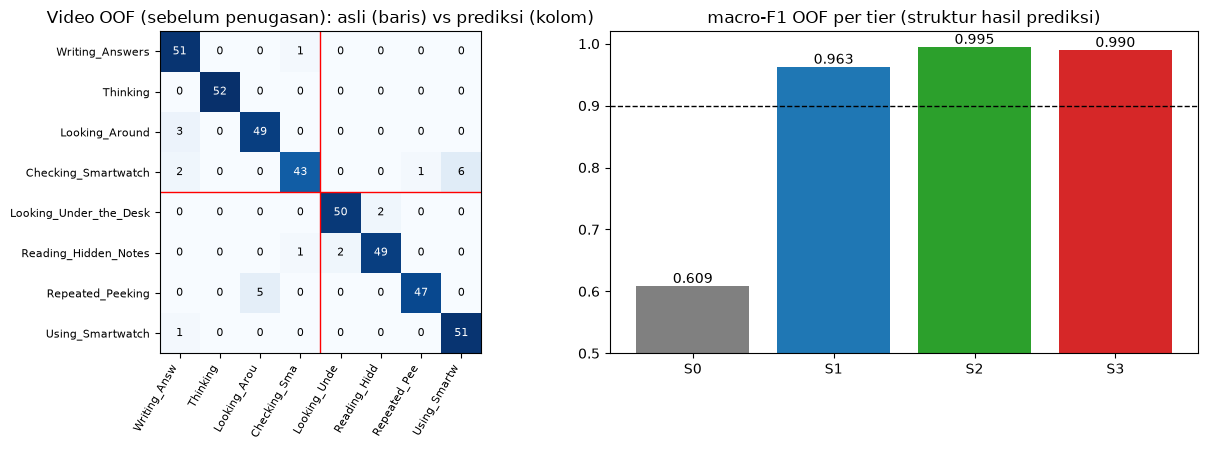

In [18]:
def geo(tags, key, fi=None):        # ensemble antar-stream: rata-rata log-probabilitas tanpa bobot
    L = [np.log((RES[t][key] if fi is None else RES[t][key][fi]) + 1e-9) for t in tags]
    P = np.exp(np.mean(L, 0))
    return P / P.sum(-1, keepdims=True)


def f1m(y, p):
    return f1_score(y, p, average="macro")


def cv_report(tags):
    lab = {k: np.zeros(N_TRC, int) for k in ("S0", "S1", "S2", "S3")}
    fz = dict(benar=0, salah=0, tidak_saling_terbaik=0, sinkroni_benar=[], sinkroni_beda_subjek=[])
    for fi, st in ST_FOLD.items():
        l, pairs, cls, mats = tier_labels(N_TRC, geo(tags, "oof_clip"), st, geo(tags, "oof_chain", fi), geo(tags, "oof_raw", fi))
        cl = np.concatenate(st["chains"])
        for k in lab:
            lab[k][cl] = l[k][cl]
        if mats is not None:                                       # kalibrasi gate fusi: label asli hanya dipakai di fold validasi
            gsub = {int(g): {chain_subject(st["chains"][i]) for i in np.where(st["grp"] == g)[0]} for g in np.unique(st["grp"])}
            for a, b, sv, mutual in pairs:
                good = len(gsub[a]) == 1 and gsub[a] == gsub[b]
                if not mutual:
                    fz["tidak_saling_terbaik"] += 1
                else:
                    fz["benar" if good else "salah"] += 1
                if good:
                    fz["sinkroni_benar"].append(sv)
            gf, gs, A = mats
            fz["sinkroni_beda_subjek"] += [float(A[i, j]) for i, a in enumerate(gf) for j, b in enumerate(gs) if not (gsub[int(a)] & gsub[int(b)])]
    Pv = geo(tags, "oof_vid")
    o1 = to_bin(Pv)                                                # oracle: video & grup asli
    o2 = o1.copy()
    for g in np.unique(VID_GRP):
        m = np.where(VID_GRP == g)[0]
        r, c = linear_sum_assignment(-np.log(Pv[m] + 1e-9)); o2[m[r]] = (c >= 4).astype(int)
    out = {"S0 klip sendiri": f1m(Y_CLIP, lab["S0"]), "S1 video": f1m(Y_CLIP, lab["S1"]), "S2 + penugasan": f1m(Y_CLIP, lab["S2"]),
           "S3 + fusi 2 kamera": f1m(Y_CLIP, lab["S3"]), "S1 oracle": f1m(Y_CLIP, o1[CLIP_VID]), "S2 oracle": f1m(Y_CLIP, o2[CLIP_VID]),
           "akurasi 8 kelas (video)": float((Pv.argmax(1) == meta.y8.values).mean()),
           "NLL 8 kelas (video)": float(-np.log(Pv[np.arange(NV), meta.y8.values] + 1e-9).mean())}
    return out, lab, Pv, fz


tags_all = [t for t, _, _ in STREAMS]
rows = {("+".join(tg)): cv_report(tg)[0] for tg in ([[t] for t in tags_all] + ([tags_all] if len(tags_all) > 1 else []))}
cv_table = pd.DataFrame(rows).T.round(4)
display(cv_table)
ENS = tags_all                                                      # semua stream dipakai; tidak ada pemilihan berbasis skor di notebook ini
rep, LAB, Pv, FZ = cv_report(ENS)

# Kapan S3 boleh jadi submission utama?  (1) di CV tidak ada pencocokan subjek antar-kamera yang salah, (2) S3 tidak lebih buruk dari S2
S3_SAFE = bool(USE_S3 and FZ["benar"] > 0 and FZ["salah"] == 0 and rep["S3 + fusi 2 kamera"] >= rep["S2 + penugasan"])
if USE_S3:
    print(f"fusi di CV: {FZ['benar']} pasangan subjek benar, {FZ['salah']} salah, {FZ['tidak_saling_terbaik']} dilewati (tidak saling-terbaik)"
          f" | sinkroni pasangan benar min {min(FZ['sinkroni_benar'], default=float('nan')):.2f}"
          f" vs subjek berbeda maks {max(FZ['sinkroni_beda_subjek'], default=float('nan')):.2f} (ambang absolut tidak dipakai)"
          f" → S3 {'LAYAK' if S3_SAFE else 'TIDAK'} jadi submission utama")
    sens = {}
    for lam in (2.0, 4.0, 8.0):                                    # sensitivitas saja; nilai yang dipakai tetap 4.0
        LAM_SYNC = lam
        sens[lam] = round(cv_report(ENS)[0]["S3 + fusi 2 kamera"], 4)
    LAM_SYNC = 4.0
    print("sensitivitas S3 terhadap LAM_SYNC:", sens)

# ketidakpastian: (a) rata-rata CV (resample 26 subjek)  (b) sebaran untuk test seukuran N_SUBJ_SIM subjek
rng = np.random.default_rng(SEED)
clip_subj = VID_SUBJ[CLIP_VID]
by_subj = {s: np.where(clip_subj == s)[0] for s in subs}
boot = {(k, m): [] for k in LAB for m in ("cv", "test")}
for _ in range(500):
    for m, n_s in (("cv", len(subs)), ("test", min(N_SUBJ_SIM, len(subs)))):
        idx = np.concatenate([by_subj[s] for s in rng.choice(subs, n_s, replace=True)])
        for k in LAB:
            boot[(k, m)].append(f1m(Y_CLIP[idx], LAB[k][idx]))
q = lambda v: (round(float(np.percentile(v, 5)), 3), round(float(np.percentile(v, 95)), 3))
unc = pd.DataFrame({"skor OOF": {k: round(f1m(Y_CLIP, LAB[k]), 4) for k in sorted(LAB)},
                    "5–95% rata-rata CV (26 subjek)": {k: q(boot[(k, "cv")]) for k in sorted(LAB)},
                    f"5–95% untuk test {min(N_SUBJ_SIM, len(subs))} subjek": {k: q(boot[(k, "test")]) for k in sorted(LAB)}})
display(unc)
per_fold = pd.DataFrame({k: [f1m(Y_CLIP[va[CLIP_VID]], LAB[k][va[CLIP_VID]]) for va in FOLDS] for k in sorted(LAB)}).round(4)
per_fold["n_subjek"] = [len(set(VID_SUBJ[va])) for va in FOLDS]
display(per_fold.rename_axis("fold"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
cmx = confusion_matrix(meta.y8.values, Pv.argmax(1), labels=range(8))
ax[0].imshow(cmx, cmap="Blues"); ax[0].set_xticks(range(8)); ax[0].set_yticks(range(8))
ax[0].set_xticklabels([b[:12] for b in BEHAVIOURS], rotation=60, ha="right", fontsize=8); ax[0].set_yticklabels(BEHAVIOURS, fontsize=8)
for i in range(8):
    for j in range(8):
        ax[0].text(j, i, cmx[i, j], ha="center", va="center", fontsize=8, color="white" if cmx[i, j] > cmx.max() / 2 else "black")
ax[0].axhline(3.5, color="r", lw=1); ax[0].axvline(3.5, color="r", lw=1); ax[0].set_title("Video OOF (sebelum penugasan): asli (baris) vs prediksi (kolom)")
ks = ["S0", "S1", "S2", "S3"]
ax[1].bar(ks, [f1m(Y_CLIP, LAB[k]) for k in ks], color=["gray", "tab:blue", "tab:green", "tab:red"])
for i, k in enumerate(ks):
    ax[1].text(i, f1m(Y_CLIP, LAB[k]) + 0.005, f"{f1m(Y_CLIP, LAB[k]):.3f}", ha="center")
ax[1].set_ylim(0.5, 1.02); ax[1].set_title("macro-F1 OOF per tier (struktur hasil prediksi)"); ax[1].axhline(0.9, color="k", ls="--", lw=1)
plt.tight_layout(); plt.show()

## 9. Prediksi test & file submission

In [19]:
P_te_clip, P_te_chain, P_te_raw = geo(ENS, "te_clip"), geo(ENS, "te_chain"), geo(ENS, "te_raw")
T_LAB, PAIRS_TE, CLS_TE, MATS_TE = tier_labels(N_TEST, P_te_clip, ST_TEST, P_te_chain, P_te_raw)
# S3 di test hanya "lengkap" bila tiap kamera punya jumlah grup lolos-gate yang sama dan semua pasangan saling-terbaik
S3_COMPLETE = bool(MATS_TE is not None and len(MATS_TE[0]) == len(MATS_TE[1]) > 0 and PAIRS_TE and all(m for *_, m in PAIRS_TE)
                   and len(MATS_TE[0]) * 2 == len(np.unique(ST_TEST["grp"])))
assert sorted(np.concatenate(ST_TEST["chains"]).tolist()) == list(range(N_TEST)), "ada sequence test yang tidak masuk rantai mana pun"
assert sorted(np.concatenate(ST_TEST["chains_raw"]).tolist()) == list(range(N_TEST))
order = pd.Series(range(N_TEST), index=test_ids)                    # posisi sequence menurut id
final = "S3" if (S3_SAFE and S3_COMPLETE) else ("S2" if (USE_STITCH and USE_ASSIGN) else ("S1" if USE_STITCH else "S0"))

n_grp = len(np.unique(ST_TEST["grp"]))
print(f"test: {len(ST_TEST['chains_raw'])} rantai mentah → {len(ST_TEST['chains'])} video | {n_grp} grup | {int(ST_TEST['ok'].sum() // PER_GROUP)} lolos gate"
      f" | video yang difusi: {int((CLS_TE >= 0).sum())}")
print("pasangan grup front–side di test (sinkroni, saling-terbaik):", [(round(sv, 2), m) for _, _, sv, m in PAIRS_TE],
      "| S3 lengkap:", S3_COMPLETE, "| S3 layak menurut CV:", S3_SAFE)
print("porsi label cheat :", {k: round(float(T_LAB[k].mean()), 3) for k in sorted(T_LAB)})
print("sequence berbeda  :", {f"{a} vs {b}": int((T_LAB[a] != T_LAB[b]).sum()) for a, b in (("S0", "S1"), ("S1", "S2"), ("S2", "S3"))})
if (CLS_TE >= 0).any():
    cnt = pd.Series(CLS_TE[CLS_TE >= 0]).map(lambda c: BEHAVIOURS[c]).value_counts()
    print("perilaku hasil fusi (tiap perilaku seharusnya muncul 2× per subjek):", cnt.to_dict())
print(f"tier tingkat video yang dipakai: {final} (file submission ditulis di bagian 10)")
display(pd.DataFrame({k: pd.Series(T_LAB[k]).value_counts() for k in sorted(T_LAB)}).rename_axis("label"))

test: 97 rantai mentah → 96 video | 12 grup | 12 lolos gate | video yang difusi: 48
pasangan grup front–side di test (sinkroni, saling-terbaik): [(0.9, True), (0.77, False), (0.79, False), (0.8, False), (0.76, True), (0.83, True)] | S3 lengkap: False | S3 layak menurut CV: False
porsi label cheat : {'S0': 0.556, 'S1': 0.495, 'S2': 0.506, 'S3': 0.506}
sequence berbeda  : {'S0 vs S1': 534, 'S1 vs S2': 48, 'S2 vs S3': 0}
perilaku hasil fusi (tiap perilaku seharusnya muncul 2× per subjek): {'Looking_Around': 6, 'Repeated_Peeking': 6, 'Looking_Under_the_Desk': 6, 'Reading_Hidden_Notes': 6, 'Thinking': 6, 'Using_Smartwatch': 6, 'Checking_Smartwatch': 6, 'Writing_Answers': 6}
tier tingkat video yang dipakai: S2 (file submission ditulis di bagian 10)


,S0,S1,S2,S3
label,,,,
0,673,765,749,749
1,842,750,766,766


## 10. Tier akhir (S5) — detik curang di dalam video *cheat* → `submission.csv`

In [20]:
def best_block(X, lo, min_len):
    """X (n, D) deskriptor berurutan -> (a, b): blok [a, b) dengan a >= lo yang paling berbeda dari sisa video
    (memaksimalkan between-cluster sum of squares antara blok dan sisanya)"""
    n = len(X)
    cs = torch.cat([X.new_zeros(1, X.shape[1]), X.cumsum(0)])
    tot, best = cs[-1], (-1.0, lo, n)
    for a in range(lo, n - min_len + 1):
        b = torch.arange(a + min_len, n + 1, device=X.device)
        m = (b - a).float()
        d = (cs[b] - cs[a]) / m[:, None] - (tot - cs[b] + cs[a]) / (n - m).clamp(min=1)[:, None]
        v = d.pow(2).sum(1) * m * (n - m) / n
        v[m >= n] = -1
        j = int(v.argmax())
        if float(v[j]) > best[0]:
            best = (float(v[j]), a, int(b[j]))
    return best[1], best[2]


# Label test diberikan PER DETIK: di video cheat, detik-detik awal (menulis biasa) berlabel normal dan hanya detik sejak aksi
# dimulai sampai akhir video yang berlabel 1.  Train tidak punya label per detik, jadi definisi ini divalidasi lewat public LB:
#   semua detik video cheat = 1 -> 0,7507 | awal aksi dideteksi per video -> 0,9700 | paruh kedua video -> 0,9784 |
#   mulai detik indeks floor((n-1)/2) -> 0,9920.  Dari skor-skor itu: tidak ada false positive, hanya detik cheat yang terlewat,
#   dan polanya cocok dengan "aksi dimulai pada detik yang SAMA di semua video" (protokol perekaman), bukan proporsi durasi.
# Detik mulai itu (ONSET_SEC) TIDAK diketik: ia diukur dari video train sebagai detik yang paling sering memuat awal aksi.
USE_LOCALIZE = str(USE_LOCALIZE).lower() in ("1", "true")
FINAL_LAB, FINAL_NAME = T_LAB[final], final
if USE_LOCALIZE and USE_STITCH:
    # (a) train: awal aksi tiap video non-"Writing_Answers", dicari per frame fitur (0,1 detik) dari perubahan fitur DINOv2
    rows = []
    for r in meta[meta.behaviour != "Writing_Answers"].itertuples():
        n = int(r.n_clips)
        Fv = torch.from_numpy(np.load(f"{A_DIR}/train/{r.key}.npy")[: n * FPC_A]).to(DEV).float().flatten(1)
        rows.append((r.behaviour, r.cls, n, best_block(Fv, FPC_A, 2 * FPC_A)[0] / FPC_A))
    loc_tr = pd.DataFrame(rows, columns=["perilaku", "kelas", "n_detik", "awal_aksi_detik"])
    display(loc_tr.groupby(["kelas", "perilaku"]).awal_aksi_detik.agg(["mean", "median"]).round(2))
    sec_hist = np.floor(loc_tr.awal_aksi_detik).astype(int).value_counts().sort_index()
    ONSET_SEC = int(sec_hist.idxmax())                               # detik (indeks dari 0) yang paling sering memuat awal aksi
    print("train — detik yang memuat awal aksi:", sec_hist.to_dict())
    print(f"korelasi awal aksi dengan durasi video: {np.corrcoef(loc_tr.awal_aksi_detik, loc_tr.n_detik)[0, 1]:.2f} (kecil -> waktu absolut)"
          f" | median {loc_tr.awal_aksi_detik.median():.2f} s | ONSET_SEC = {ONSET_SEC}")
    # (b) test: pada tiap video yang diprediksi cheat oleh tier S2, sequence ke-ONSET_SEC dan seterusnya berlabel 1
    lab, n_cheat = np.zeros(N_TEST, int), 0
    for ch in ST_TEST["chains"]:
        c = np.asarray(ch)
        if T_LAB["S2"][c[0]] == 0:
            continue
        n_cheat += 1
        if len(c) < MIN_LEN:                                         # potongan video yang tidak utuh: posisi tidak diketahui -> ikut label video
            lab[c] = 1
        else:
            lab[c[ONSET_SEC:]] = 1
    free_gpu()
    FINAL_LAB, FINAL_NAME = lab, f"S5 (video cheat: label 1 sejak detik indeks {ONSET_SEC} sampai akhir)"
    print(f"{n_cheat} video cheat | sequence berlabel curang: {int(lab.sum())} = {lab.sum() / max(T_LAB['S2'].sum(), 1):.3f} dari sequence video cheat")

SUB_PATH = os.path.join(OUT_DIR, "submission_FAST.csv" if FAST else "submission.csv")   # FAST tidak boleh menimpa submission sungguhan
sub = sub_tmpl[["id"]].copy()
sub["label"] = FINAL_LAB[order.loc[sub.id].values].astype(int)
assert len(sub) == len(sub_tmpl) and sub.label.isin([0, 1]).all() and sub.label.notna().all() and (sub.id == sub_tmpl.id).all()
sub.to_csv(SUB_PATH, index=False)
print(f"{os.path.abspath(SUB_PATH)} ditulis | tier: {FINAL_NAME} | {len(sub)} baris | cheat {int(sub.label.sum())}, normal {int((sub.label == 0).sum())}")
print(f"total waktu notebook: {(time.time() - T_START) / 60:.1f} menit")

mean  median
kelas  perilaku                            
cheat  Looking_Under_the_Desk  7.70     7.9
       Reading_Hidden_Notes    8.37     8.1
       Repeated_Peeking        7.80     7.8
       Using_Smartwatch        7.43     8.1
normal Checking_Smartwatch     7.32     7.6
       Looking_Around          7.99     7.7
       Thinking                7.55     7.8

train — detik yang memuat awal aksi: {1: 6, 2: 7, 3: 4, 4: 1, 5: 10, 6: 27, 7: 152, 8: 114, 9: 19, 10: 11, 11: 7, 12: 3, 13: 3}
korelasi awal aksi dengan durasi video: 0.12 (kecil -> waktu absolut) | median 7.90 s | ONSET_SEC = 7
48 video cheat | sequence berlabel curang: 430 = 0.561 dari sequence video cheat
D:\ITS\S1\Lomba\Dataslayer\Penyisihan\submission.csv ditulis | tier: S5 (video cheat: label 1 sejak detik indeks 7 sampai akhir) | 1515 baris | cheat 430, normal 1085
total waktu notebook: 29.7 menit
